In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

In [4]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [5]:
#remove day sept 26th (bad recording)

#remove bad experiment 
# Convert recording_date safely
big_df["recording_date"] = pd.to_datetime(big_df["recording_date"], errors="coerce")

# Remove all recordings from Sept 26, 2025
remove_date = pd.to_datetime("2025-09-26")
big_df = big_df[big_df["recording_date"] != remove_date]

#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [12]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C54","C90"},
    "MAOA2":{"H9", "C12", "C3", "C54","C90"},
    "MAOA3":{"H9", "C12", "C3", "C54","C90"},
    "MAOA72": {"C12", "C90", "C54", },
    "MAOA76": {"C12", "C90", "C54"},
    "MAOA77": {"C12", "C90", "C54"},
}

In [13]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 90 rows based on plate-specific clone removal.


In [14]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B3,"[0.7793130012355004, 1.3467926472630483]","[0.058214372561458665, 0.07832226183330862]",0.078509,0.001454,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[5.249566655100951, 0.0006597419448411399, nan...","[0.17747058316226666, nan, nan, 0.085106710884...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,C3,"[0.21100432373004913, 0.5144354348027547]","[0.019264464789361287, 0.013335276310084031]",0.000000,0.001066,"[C3_11, C3_12, C3_13, C3_14, C3_15, C3_16, C3_...","[nan, 0.0006597419448411399, nan, 1.0404130470...","[nan, nan, nan, 0.0164935486210285, nan, nan, ...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,A4,"[0.004241748910561047, 0.009775569618114778]","[nan, nan]",0.000000,0.232831,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.0008220443625118308, nan, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
878,B1,"[0.26199502345978026, 0.7419211332715153]","[0.02757010323501217, 0.025920461645713547]",0.000000,0.046000,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[nan, 0.0008220443625118308, 0.002466133087535...","[nan, nan, nan, nan, 0.01808497597526028, nan,...",2025-10-30,10.30.2025,MAOA76,C3,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
879,B2,"[0.4753718139533415, 1.490921272006652]","[0.03565617422395066, 0.04528512776359013]",0.000000,0.037999,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.024661330875354926, 0.17920567102757912, 0....","[nan, 0.007398399262606477, 0.0024661330875354...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
880,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


### Exp 3 analysis for Paper Figure

In [15]:
# Updated palette using the specific genetic strings as keys
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C", 
    "Xa:MUT/Xi:WT": "#EAC3EB", 
    "MAOA/B$^{-/Y}$": "#E980C0"  # Note the $ and ^
}

PLOT_ORDER = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B$^{-/Y}$"]



FEATURE: FIRING


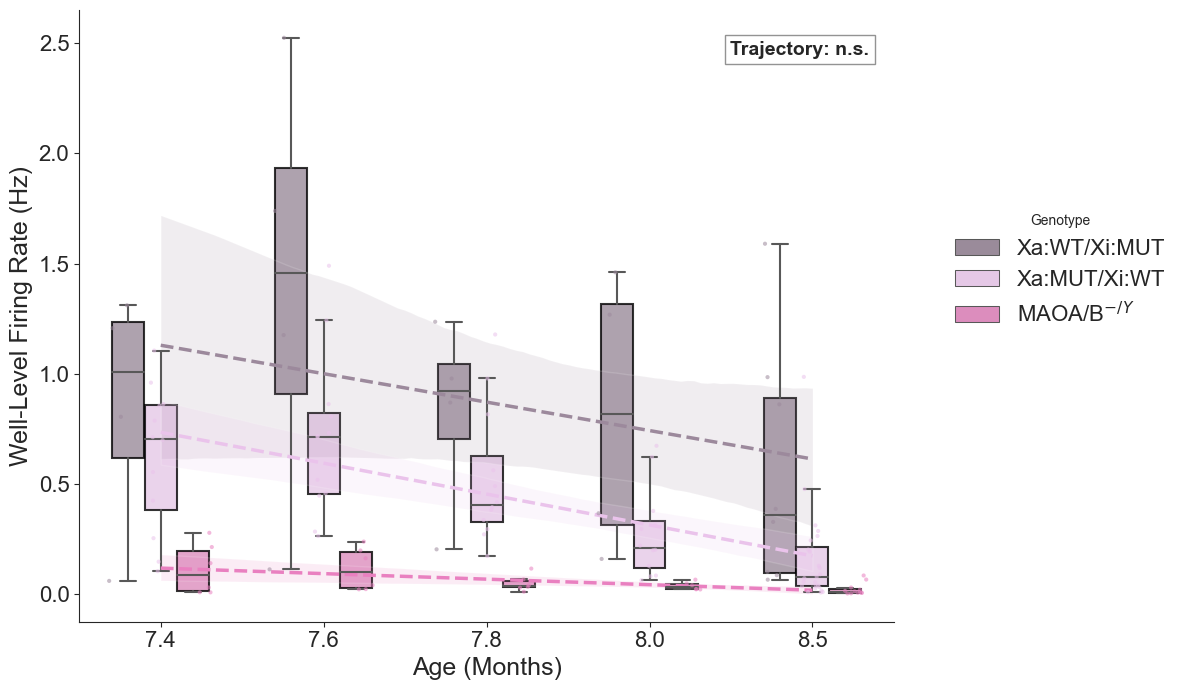

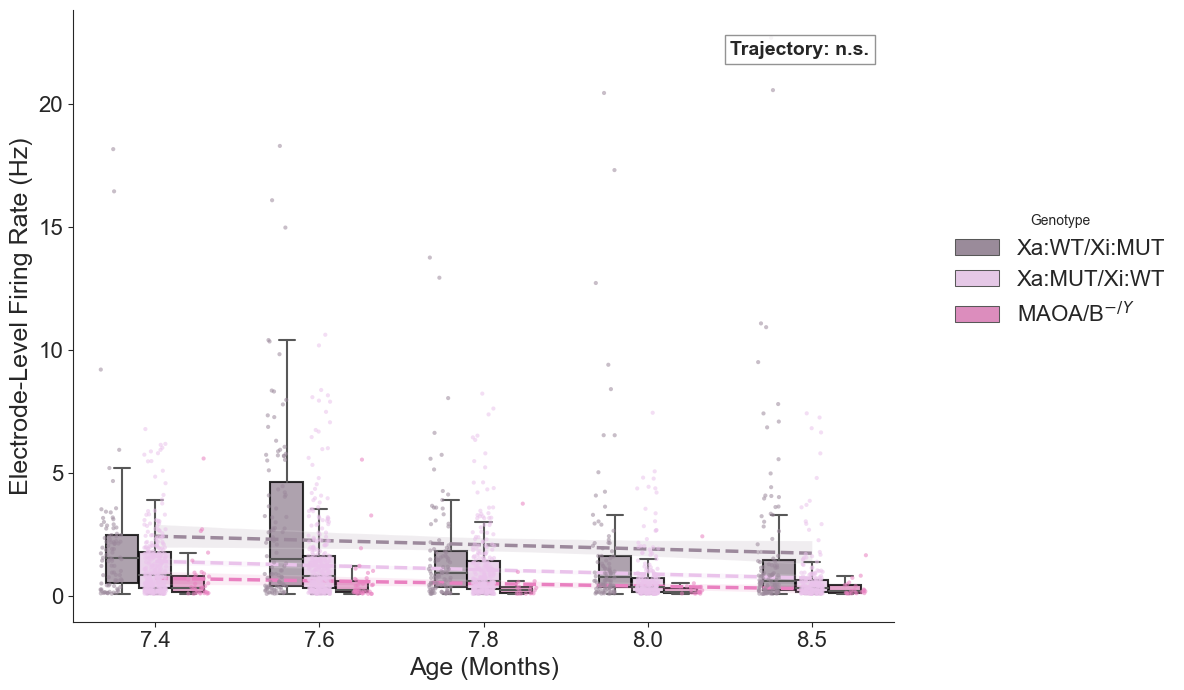


--- WELL-LEVEL STATS ---
ANOVA Interaction:
                          sum_sq     df          F        PR(>F)
C(group)               8.584485    2.0  37.643015  2.387430e-13
C(time_val)            4.103016    4.0   8.995874  2.271158e-06
C(group):C(time_val)   1.384659    8.0   1.517935  1.582309e-01
Residual              13.340917  117.0        NaN           NaN
Time-Point Table:
  Time  ANOVA_p  MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT  MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4 0.006516                          0.0198                          0.0094                        0.5045
  7.6 0.002838                          0.0629                          0.0021                        0.0687
  7.8 0.001603                          0.0114                          0.0018                        0.2112
  8.0 0.002610                          0.2824                          0.0020                        0.0143
  8.5 0.000532                          0.3606                        

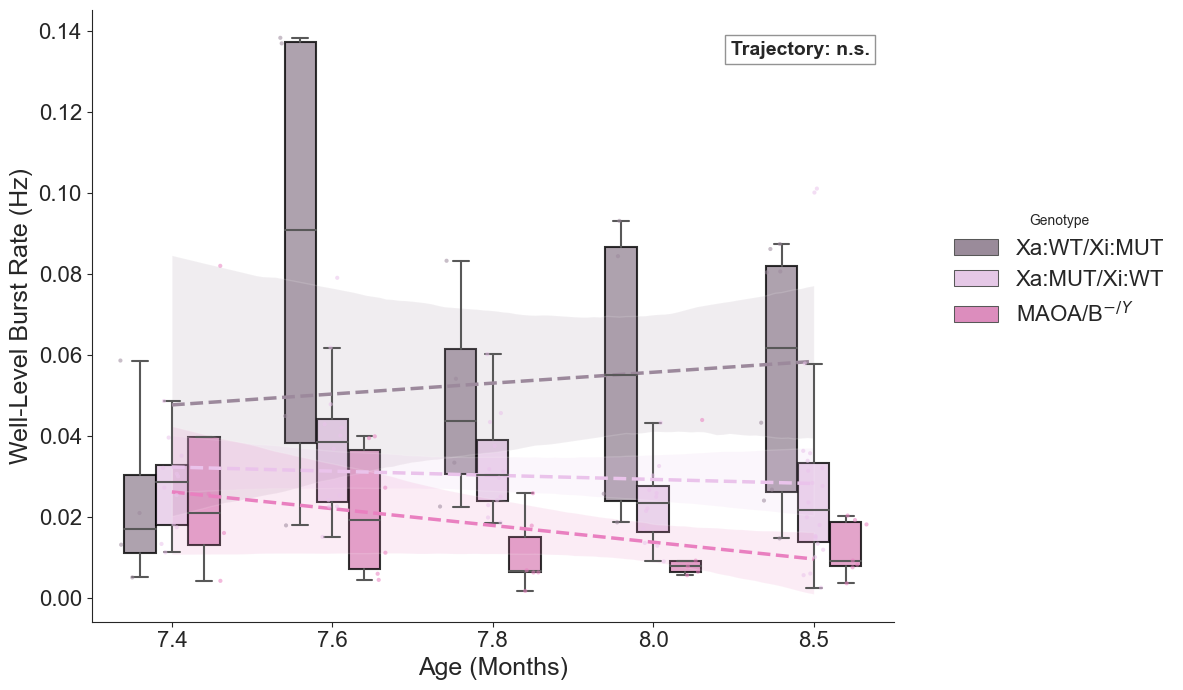

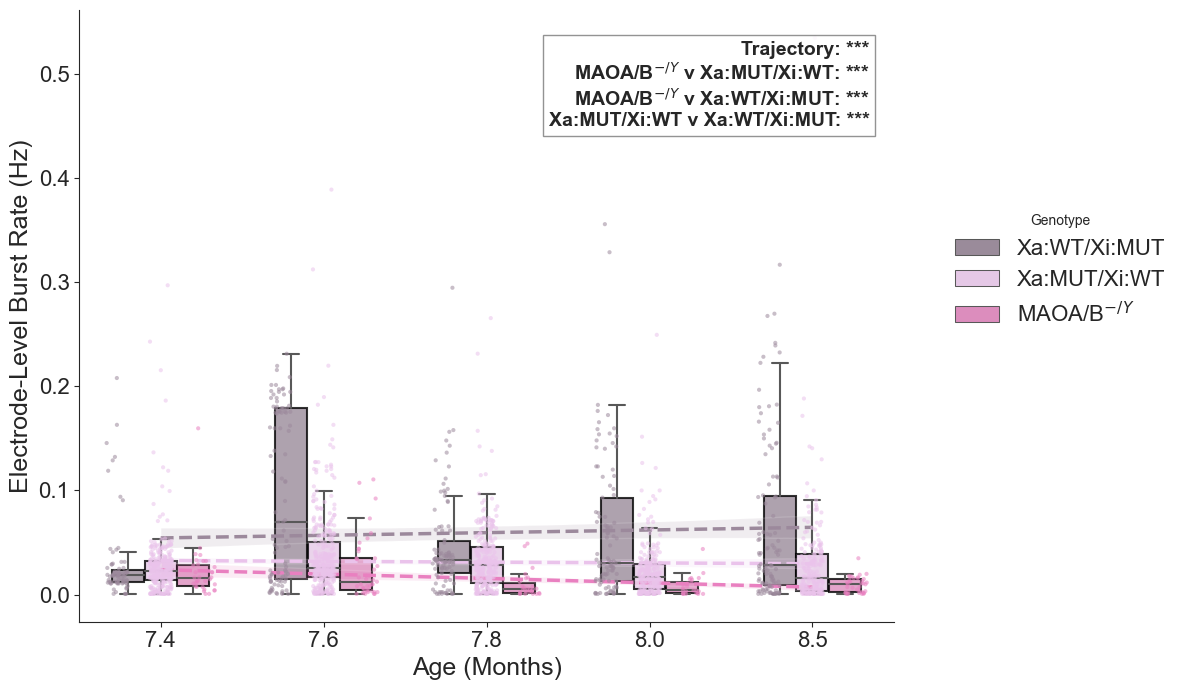


--- WELL-LEVEL STATS ---
ANOVA Interaction:
                         sum_sq     df          F        PR(>F)
C(group)              0.018424    2.0  17.631988  2.406871e-07
C(time_val)           0.003646    4.0   1.744808  1.455082e-01
C(group):C(time_val)  0.006689    8.0   1.600255  1.332030e-01
Residual              0.055905  107.0        NaN           NaN
Time-Point Table:
  Time  ANOVA_p  MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT  MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4 0.861512                             NaN                             NaN                           NaN
  7.6 0.011870                          0.4989                          0.0101                        0.0365
  7.8 0.002770                          0.0232                          0.0026                        0.1837
  8.0 0.012039                          0.6744                          0.0135                        0.0239
  8.5 0.007533                          0.2914                          0.0

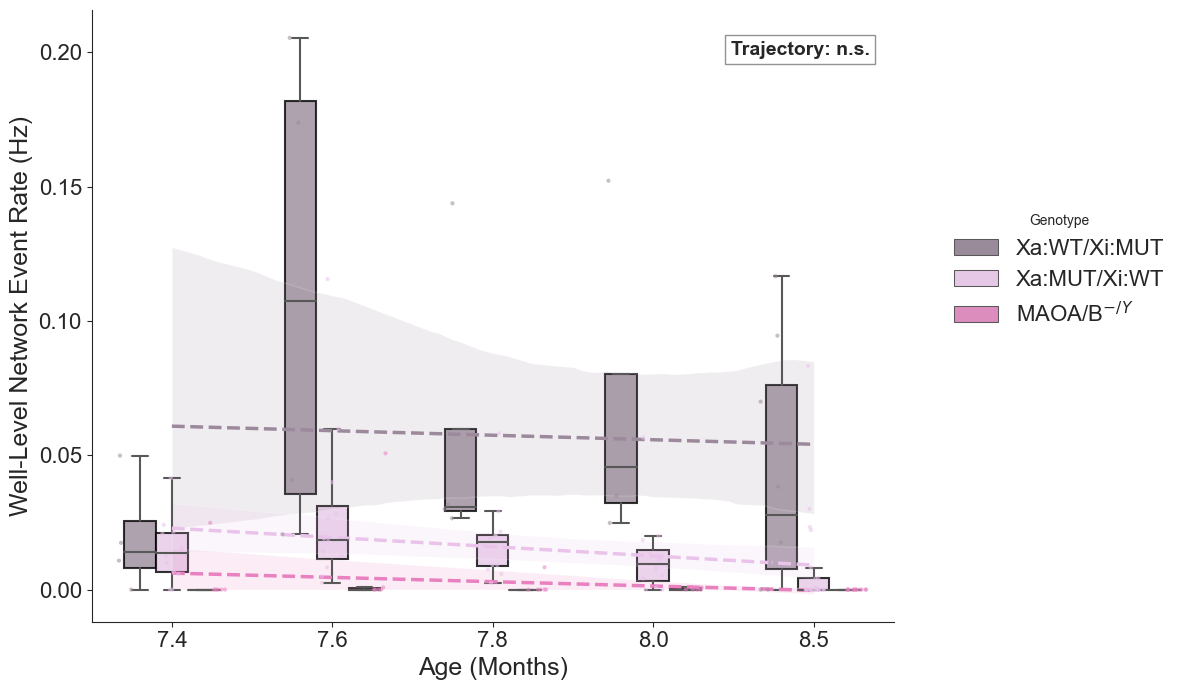


--- WELL-LEVEL STATS ---
ANOVA Interaction:
                         sum_sq     df          F        PR(>F)
C(group)              0.045649    2.0  29.817362  3.427062e-11
C(time_val)           0.011375    4.0   3.714926  6.961511e-03
C(group):C(time_val)  0.011794    8.0   1.925936  6.235615e-02
Residual              0.089561  117.0        NaN           NaN
Time-Point Table:
  Time  ANOVA_p  MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT  MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4 0.183794                             NaN                             NaN                           NaN
  7.6 0.006865                          0.6432                          0.0069                        0.0157
  7.8 0.009146                          0.4007                          0.0073                        0.0357
  8.0 0.001993                          0.6204                          0.0022                        0.0048
  8.5 0.000421                          0.6450                          0.0

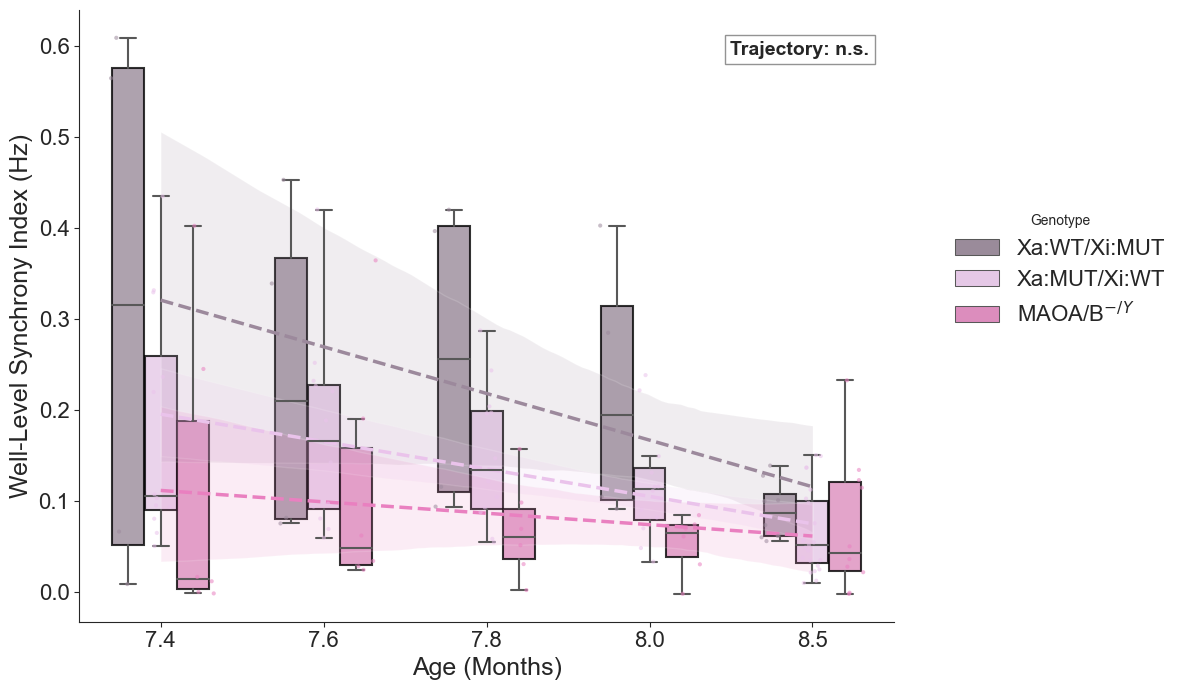


--- WELL-LEVEL STATS ---
ANOVA Interaction:
                         sum_sq     df         F    PR(>F)
C(group)              0.205662    2.0  8.750758  0.000291
C(time_val)           0.257486    4.0  5.477930  0.000453
C(group):C(time_val)  0.082093    8.0  0.873250  0.541325
Residual              1.339624  114.0       NaN       NaN
Time-Point Table:
  Time  ANOVA_p  MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT  MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4 0.258096                             NaN                             NaN                           NaN
  7.6 0.375970                             NaN                             NaN                           NaN
  7.8 0.020931                          0.2229                          0.0160                        0.1501
  8.0 0.012451                          0.2498                          0.0092                        0.0798
  8.5 0.524692                             NaN                             NaN                      

In [16]:
# You can pass your custom palette directly
my_stats = run_mea_analysis_for_figure(
    big_df, 
    experiment='Exp3', unit = "months",
    palette=MAOA_FIGURE_PALETTE
)


--- GENERATING GROUPED PLOTS FOR FIRING ---


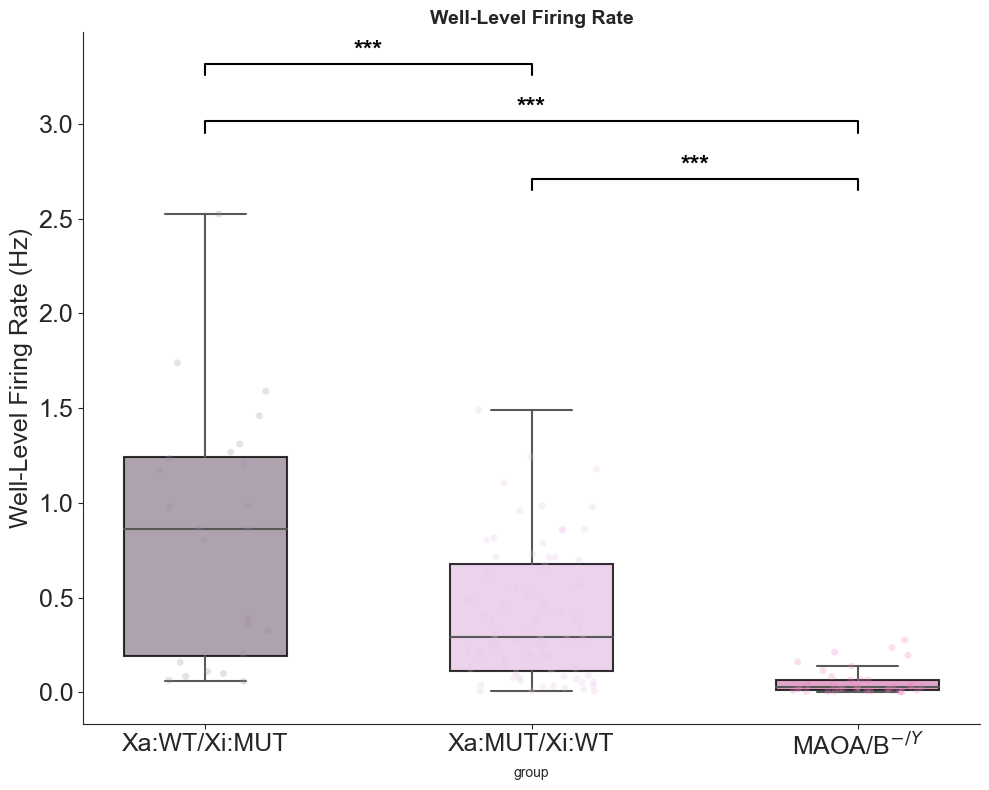

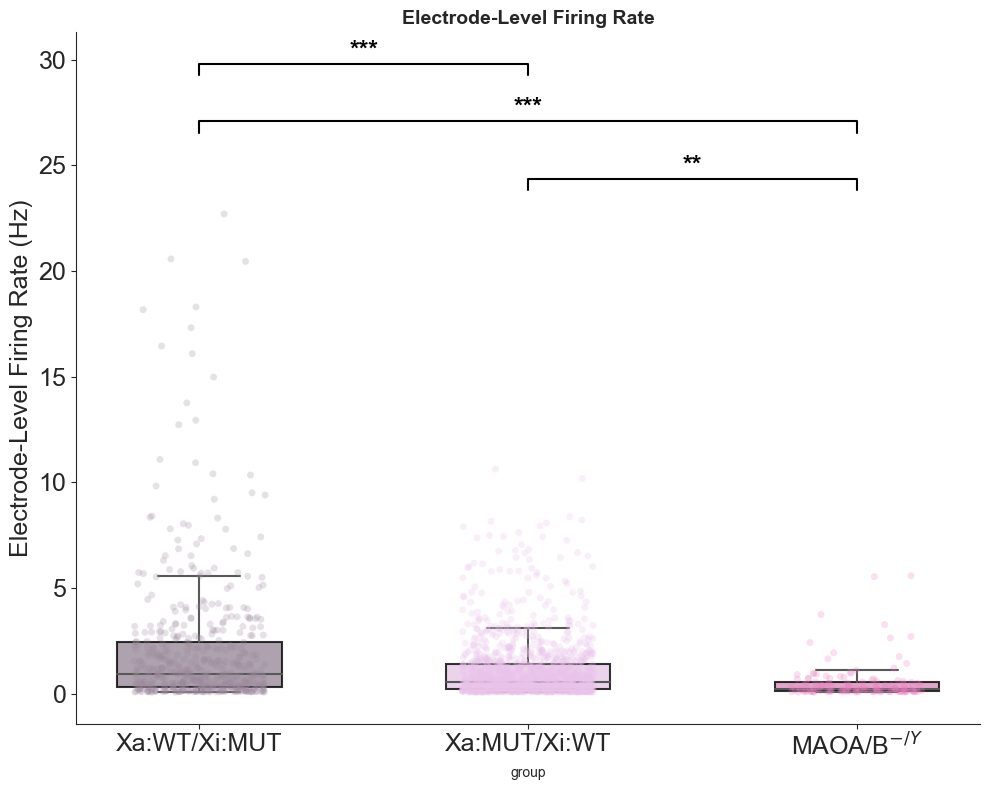


--- GENERATING GROUPED PLOTS FOR BURST ---


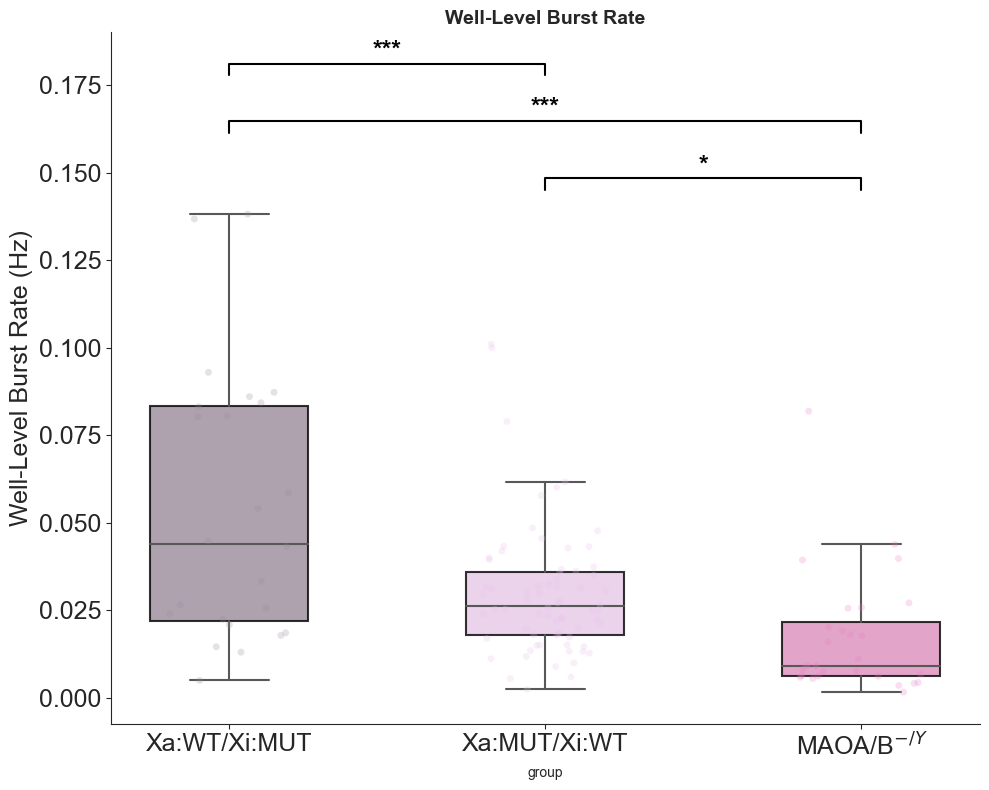

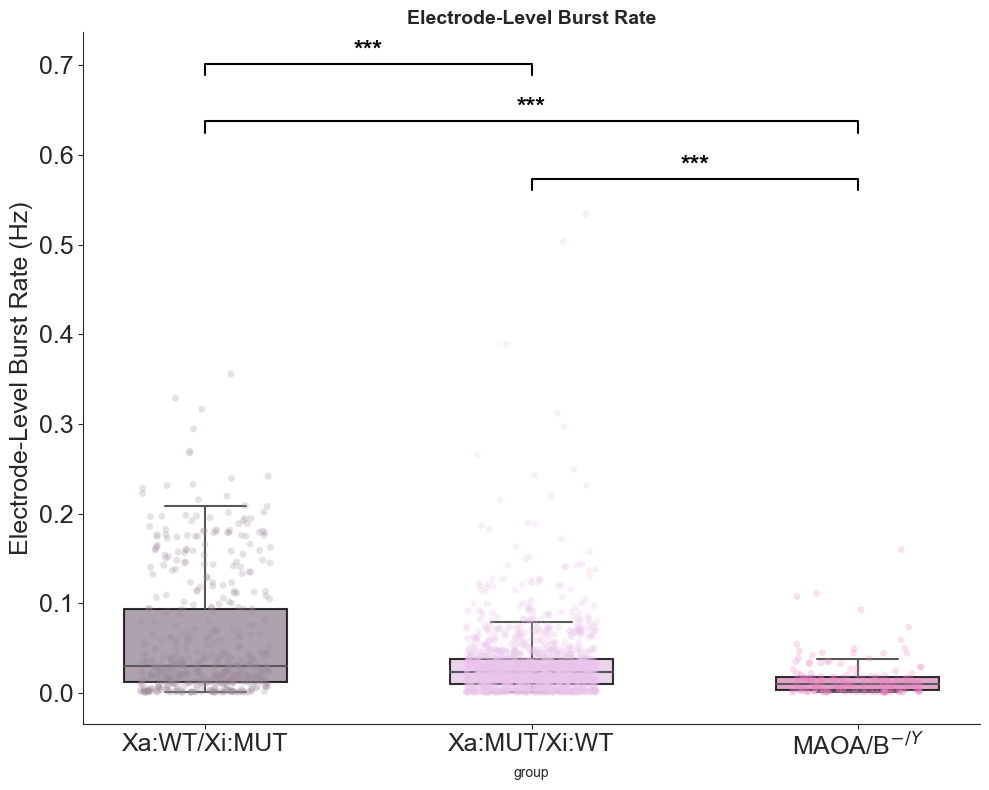


--- GENERATING GROUPED PLOTS FOR NETWORK ---


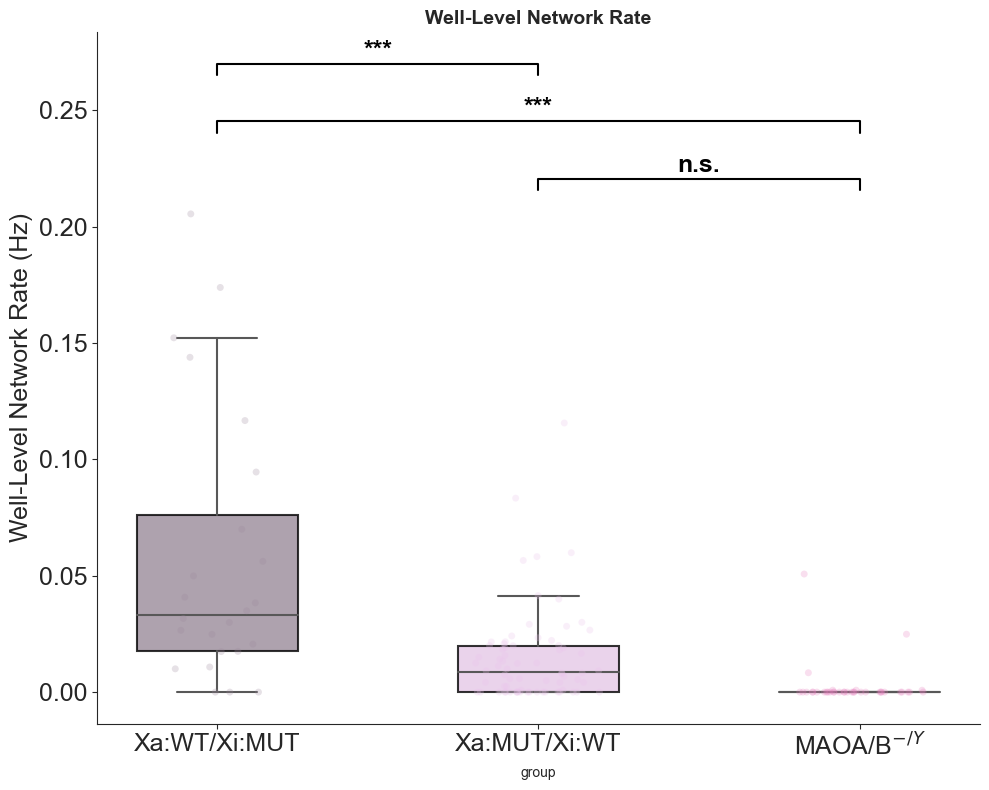


--- GENERATING GROUPED PLOTS FOR SYNCHRONY ---


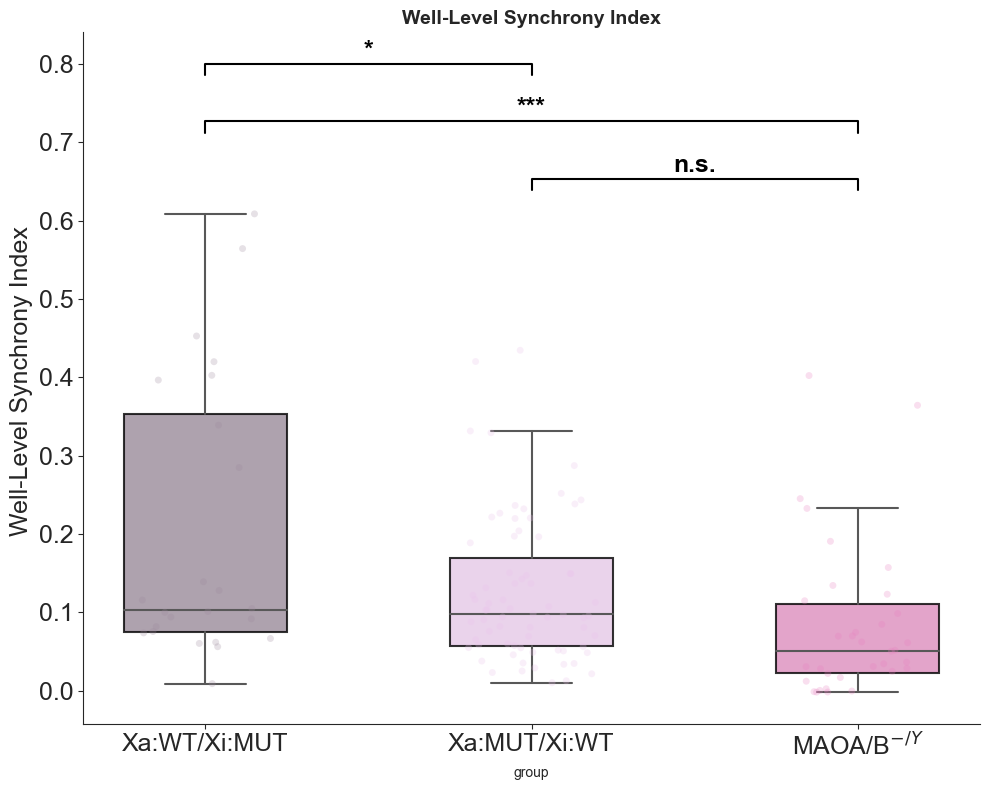

In [17]:



run_grouped_analysis(big_df, "Exp3")